# 黄色奶蛙视频目标检测

> 输入：`res/nl_yellow_video.mp4`（**1280×720、25 fps、475 帧、19 秒**）
> 目标：**黄色奶蛙**（白底多宫格动画，画面上同时可能出现 1～4 只）
> 方法：**必修讲义第 3 章（HSV 颜色空间）+ 第 5 章（`inRange` 二值化）+ 第 5 章第 4 节（轮廓 → 外接矩形）+ 第 6 章（形态学）+ 第 10 章（画图）**，最后用第 1 章的 `VideoWriter` 存成视频。

## 思路（一句话）

奶蛙是**纯黄色**、背景是**白底**，所以不需要深度学习模型 ——
**「按颜色切出掩膜 → 把掩膜清理干净 → 找轮廓 → 取外接矩形」** 就够了。

```text
读帧 → BGR2HSV_FULL → inRange(黄色区间) → 开运算去噪 → 闭运算补洞
     → findContours → 按面积筛 → boundingRect → 画框 → 写进输出视频
```

> ⚠️ **两个前提**：① 目标颜色和背景**差别明显**；② 光照**别太剧烈**。
> 这两条只要有一条不成立，颜色分割就会失效 —— 那时候才需要上 YOLO（就是教材第 2 章讲的东西）。

**怎么用这份文件**：从头往下跑就行。每一步都有配图和真实输出，参数可以直接改了看效果。

In [26]:
# ===== 起手式：和讲义一致 =====
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
import os

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'WenQuanYi Micro Hei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 60


def show_img(*imgs, titles=None, cmap=None, figsize=None):
    """并排显示多张图（和讲义里的 show_img 用法一样）。"""
    n = len(imgs)
    titles = list(titles or [''] * n)
    fig, axes = plt.subplots(1, n, figsize=figsize or (min(5.0 * n, 20.0), 4.6))
    if n == 1:
        axes = [axes]
    for ax, im, t in zip(axes, imgs, titles):
        if im.ndim == 2:
            ax.imshow(im, cmap=cmap or 'gray')
        else:
            ax.imshow(im[:, :, ::-1])
        if t:
            ax.set_title(t, fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()


print('OpenCV', cv2.__version__, '| numpy', np.__version__)

OpenCV 4.13.0 | numpy 2.4.3


In [27]:
print('=== 1. 先摸清素材 ===')
cap = cv2.VideoCapture('res/nl_yellow_video.mp4')
assert cap.isOpened(), '打不开视频，检查路径'

FPS = cap.get(cv2.CAP_PROP_FPS)
W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
N = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f'分辨率 {W}x{H}   fps={FPS}   总帧数={N}   时长={N / FPS:.1f} 秒')
print('↑ 这三个数后面写 VideoWriter 时都要用（frameSize 的顺序是 (宽, 高)！）')

=== 1. 先摸清素材 ===
分辨率 1280x720   fps=25.0   总帧数=475   时长=19.0 秒
↑ 这三个数后面写 VideoWriter 时都要用（frameSize 的顺序是 (宽, 高)！）


---
## 第 1 步：黄色区间怎么定？

**不能凭感觉写数字**。正确做法是**从图里采样**：把「饱和度高、又不太暗」的像素挑出来，
看它们的 **H 通道分位数**落在哪。

- 为什么要 `S > 60`：白色的 S **接近 0**（背景是白底），这个条件直接把背景排掉；
- 为什么要 `V > 120`：太暗的像素 H 没有意义（阴影、黑眼睛周围）；
- 为什么看 **H**：光照变化时 H 几乎不变（讲义第 3 章 3.4 节的结论）。

⚠️ 本讲义统一用 **`COLOR_BGR2HSV_FULL`**（H 是 0~255）；用成 `COLOR_BGR2HSV`（H 是 0~179）的话，
区间全都要换算，**这是最常见的翻车点**。

In [28]:
print('=== 2. 采样：看黄色像素的 H 落在哪 ===')
meds, p95s = [], []
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
for idx in [0, 118, 237, 356, 474]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, fr = cap.read()
    if not ok:
        continue
    hsv = cv2.cvtColor(fr, cv2.COLOR_BGR2HSV_FULL)
    Hc, Sc, Vc = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
    m = (Sc > 60) & (Vc > 120)                       # 先排掉白底和暗部
    meds.append(float(np.percentile(Hc[m], 50)))
    p95s.append(float(np.percentile(Hc[m], 95)))
    print(f'frame {idx:3d}: 候选像素 {100 * m.sum() / m.size:5.1f}%  '
          f'H p5={np.percentile(Hc[m], 5):5.1f}  p50={np.percentile(Hc[m], 50):5.1f}  '
          f'p95={np.percentile(Hc[m], 95):5.1f}   S中位={np.percentile(Sc[m], 50):.0f}  '
          f'V中位={np.percentile(Vc[m], 50):.0f}')
print()
print(f'→ 各帧 H 的中位数在 {min(meds):.0f}~{max(meds):.0f} 之间，p95 最高 {max(p95s):.0f}；所以取 H 25~55 留足余量，再加 S>=60、V>=120。')
print('  讲义第 3 章的颜色区间表里「黄 = 31~48」，和实测完全对得上。')

=== 2. 采样：看黄色像素的 H 落在哪 ===
frame   0: 候选像素  20.0%  H p5= 25.0  p50= 32.0  p95= 42.0   S中位=156  V中位=240
frame 118: 候选像素  29.0%  H p5= 30.0  p50= 35.0  p95= 42.0   S中位=122  V中位=209
frame 237: 候选像素  24.6%  H p5= 28.0  p50= 34.0  p95= 42.0   S中位=145  V中位=225
frame 356: 候选像素  27.1%  H p5= 27.0  p50= 32.0  p95= 42.0   S中位=155  V中位=227
frame 474: 候选像素  28.3%  H p5= 22.0  p50= 33.0  p95= 44.0   S中位=150  V中位=238

→ 各帧 H 的中位数在 32~35 之间，p95 最高 44；所以取 H 25~55 留足余量，再加 S>=60、V>=120。
  讲义第 3 章的颜色区间表里「黄 = 31~48」，和实测完全对得上。


---
## 第 2 步：从一帧开始，把每一步都看一眼

先把**单帧**的流水线跑通、每一步的中间结果都显示出来 —— 这比直接调参快得多。

**两个形态学操作各解决什么**：

| 操作 | 治什么 | 用多大核 |
| --- | --- | --- |
| **开运算** `MORPH_OPEN` | 抹掉掩膜上的**小白点**（噪声、反光） | 9×9 |
| **闭运算** `MORPH_CLOSE` | **补小洞 / 把断开的部分连起来** | 15×15 |

> 💡 **为什么必须闭运算**：奶蛙的眼睛是黑的、嘴是红的，黄色掩膜上会被挖出洞；
> 更麻烦的是**身上的浅色高光**会把身体切成好几块。没有闭运算，一只奶蛙会变成 2~3 个碎片，
> 框也就变成好几个小框（**差多少跑下面第 7 步的对比表就知道** —— 那格把两种核都跑一遍、当场算出来，不写死数字）。

**关于面积筛选**：`min_area` 是「小于多少像素的连通块直接丢掉」。
实测取 **3000** 就能滤掉反光小点，同时保住画面边缘那种**只露出一半**的奶蛙。

=== 3. 单帧全流程（用第 237 帧举例）===
demo frame: (720, 1280, 3)
掩膜前景占比: inRange 24.23%  -> 开运算 24.10%  -> 闭运算 24.21%


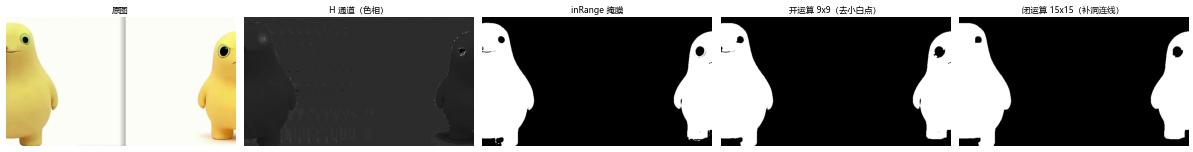

In [29]:
print('=== 3. 单帧全流程（用第 237 帧举例）===')
LO = np.array([25, 60, 120])      # HSV_FULL：H 25~55 = 黄，S/V 下限排掉白底和暗部
HI = np.array([55, 255, 255])
MIN_AREA = 3000

cap.set(cv2.CAP_PROP_POS_FRAMES, 237)
ok, demo = cap.read()
print('demo frame:', demo.shape)

hsv = cv2.cvtColor(demo, cv2.COLOR_BGR2HSV_FULL)
mask = cv2.inRange(hsv, LO, HI)
k_open = np.ones((9, 9), np.uint8)
k_close = np.ones((15, 15), np.uint8)
opened = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k_open)
closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, k_close)
print(f'掩膜前景占比: inRange {100 * np.count_nonzero(mask) / mask.size:5.2f}%  '
      f'-> 开运算 {100 * np.count_nonzero(opened) / opened.size:5.2f}%  '
      f'-> 闭运算 {100 * np.count_nonzero(closed) / closed.size:5.2f}%')

show_img(demo, hsv[:, :, 0], mask, opened, closed,
         titles=['原图', 'H 通道（色相）', 'inRange 掩膜', '开运算 9x9（去小白点）', '闭运算 15x15（补洞连线）'])

---
## 第 3 步：轮廓 → 外接矩形 → 画框

掩膜只告诉你「哪些像素是奶蛙」，要变成「**一只奶蛙在哪、多大**」还得：

```python
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
for c in contours:
    if cv2.contourArea(c) < MIN_AREA:      # 小碎块不要
        continue
    x, y, w, h = cv2.boundingRect(c)       # 正外接矩形
```

四个要点（讲义第 5 章第 4 节都讲过）：

1. `findContours` 的输入**必须是单通道二值图**（掩膜正好是）；
2. 返回值是 **`(contours, hierarchy)` 两个**，用不上层级就写 `_` 接住；
3. `RETR_EXTERNAL` = **只要最外层**（这里正好：一只奶蛙就是一个外形轮廓）；
4. **用完了要按面积从大到小排序** —— 后面画框时「最大的一只」排第一，报告也好写。

> ⚠️ **掩膜全黑时 `contours` 是空列表**，`max(contours, ...)` 会抛
> `ValueError: max() arg is an empty sequence`。下面用面积筛选时天然绕过了这个坑，
> 但如果你要写 `max()`，**先判断 `if contours:`**。

=== 4. 封装成 detect()：给一帧，返回所有目标的 bbox ===
检出 2 个目标：
  #1  bbox=(0, 34, 290, 686)  面积=139156
  #2  bbox=(1068, 80, 212, 602)  面积=86089


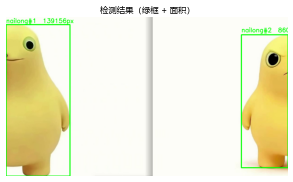

In [30]:
print('=== 4. 封装成 detect()：给一帧，返回所有目标的 bbox ===')


def detect(frame_bgr, lower=LO, upper=HI, min_area=MIN_AREA):
    """颜色分割 + 形态学清理 + 找轮廓，返回 [(x, y, w, h, area), ...]（按面积从大到小）。"""
    hsv = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2HSV_FULL)
    mask = cv2.inRange(hsv, lower, upper)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((9, 9), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out = []
    for c in contours:
        a = cv2.contourArea(c)
        if a < min_area:
            continue
        x, y, w, h = cv2.boundingRect(c)
        out.append((x, y, w, h, int(a)))
    out.sort(key=lambda b: -b[4])
    return out


def annotate(frame_bgr, boxes, color=(0, 255, 0)):
    """把框和面积画在图上，返回新图（不改原图）。"""
    vis = frame_bgr.copy()
    for i, (x, y, w, h, a) in enumerate(boxes):
        cv2.rectangle(vis, (x, y), (x + w, y + h), color, 4)
        cv2.putText(vis, f'nailong#{i + 1}  {a}px', (x, max(y - 12, 26)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, color, 2)
    return vis


boxes = detect(demo)
print(f'检出 {len(boxes)} 个目标：')
for i, (x, y, w, h, a) in enumerate(boxes):
    print(f'  #{i + 1}  bbox=({x}, {y}, {w}, {h})  面积={a}')
show_img(annotate(demo, boxes), titles=['检测结果（绿框 + 面积）'])

---
## 第 4 步：跑整段视频，存成结果视频

逐帧检测没什么神秘的，**循环 + `VideoWriter`** 而已。但有 **5 个坑**必须注意（全是讲义里强调过的）：

1. **`VideoWriter` 的 `frameSize` 是 `(宽, 高)`** —— 和 `img.shape` **反着**。写错了**不报错**，
   只会静默生成一个 **0 字节**的文件；
2. **每帧的尺寸必须和 `frameSize` 完全一致**，否则写进去的帧被丢掉；
3. **`fourcc` 和扩展名要配套**：`.avi` 常用 `MJPG` / `XVID`，`.mp4` 用 `mp4v`。
   ⚠️ **本文件用 `.mp4` + `mp4v`** —— 我一开始写的是 `.avi` + `MJPG`：
   OpenCV 能正常写、也能自己读回来（475 帧一帧不差），但**很多播放器打不开 MJPEG 的 AVI**。
   换成 `mp4v`（MPEG-4）之后兼容性好得多，**文件只有原来的 1/4 左右**。
   这类"OpenCV 读得回来、播放器打不开"的情况，**光看 `isOpened()` 是发现不了的**；
4. **`try/except` 要包住"每一帧"**，而不是包住整个循环 —— 单帧出错不该毁掉整段视频；
5. **`release()` 千万别忘** —— 文件头没写完，视频直接打不开。

> 💡 还有一个「教科书上的坑」：**视频推理必须加 `stream=True`**。
> 那是 **Ultralytics/YOLO** 的要求（不加会把所有结果堆在内存里直到 OOM，教材 2.6 节实测过）。
> 我们这里是**纯 OpenCV，逐帧读、随手丢**，不存在这个问题 —— 别把两件事搞混。

In [31]:
print('=== 5. 全片跑一遍 + 写结果视频 ===')
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
os.makedirs('out', exist_ok=True)

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
writer = None
try:
    writer = cv2.VideoWriter('out/nl_yellow_result.mp4', fourcc, FPS, (W, H))
except cv2.error as e:
    print('! 创建 VideoWriter 失败：', str(e).strip().splitlines()[-1])
if writer is not None and not writer.isOpened():
    print('! VideoWriter 打不开 —— 检查 out/ 能不能写、fourcc 和扩展名配不配套')
    writer = None
print(f'VideoWriter 可用 = {writer is not None}   (frameSize 必须是 (宽, 高) = ({W}, {H}))')

n_frames = 0
hit_frames = 0
total_boxes = 0
max_area = 0
per_frame = []
t0 = time.perf_counter()

while True:
    ok, frame = cap.read()
    if not ok:
        break
    try:
        boxes = detect(frame)
        vis = annotate(frame, boxes)
        cv2.putText(vis, f'frame {n_frames:3d}   targets {len(boxes)}', (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 255), 3)
    except Exception as e:                       # 单帧出错就跳过，别毁掉整段
        print('跳过一帧：', e)
        vis = frame
        boxes = []
    if writer is not None:
        writer.write(vis)

    n_frames += 1
    if boxes:
        hit_frames += 1
    total_boxes += len(boxes)
    per_frame.append(len(boxes))
    if boxes:
        max_area = max(max_area, max(b[4] for b in boxes))

cap.release()
if writer is not None:
    writer.release()
elapsed = time.perf_counter() - t0

import collections
dist = dict(sorted(collections.Counter(per_frame).items()))
print()
print(f'处理帧数     : {n_frames}')
print(f'有检出帧数   : {hit_frames}  ({100 * hit_frames / n_frames:.1f}%)')
print(f'累计目标个数 : {total_boxes}   （平均 {total_boxes / n_frames:.2f} 个/帧）')
print(f'每帧目标数分布: {dist}')
print(f'最大目标面积 : {max_area} px^2')
print(f'总耗时       : {elapsed:.2f} s   平均 {elapsed / n_frames * 1000:.1f} ms/帧   等效 {n_frames / elapsed:.1f} fps')
print()
if writer is not None:
    print('结果视频已写出: out/nl_yellow_result.mp4  （%d 帧）' % n_frames)
else:
    print('!! 这一轮没有写出视频（VideoWriter 不可用）—— 检查 out/ 目录能不能写、fourcc 配不配套')

=== 5. 全片跑一遍 + 写结果视频 ===
VideoWriter 可用 = True   (frameSize 必须是 (宽, 高) = (1280, 720))

处理帧数     : 475
有检出帧数   : 475  (100.0%)
累计目标个数 : 639   （平均 1.35 个/帧）
每帧目标数分布: {1: 313, 2: 160, 3: 2}
最大目标面积 : 347645 px^2
总耗时       : 4.10 s   平均 8.6 ms/帧   等效 115.8 fps

结果视频已写出: out/nl_yellow_result.mp4  （475 帧）


---
## 第 5 步：挑几帧看看效果

统计数字看不出去没出问题，**一定要肉眼看几帧**。下面挑**首帧 / 中间 / 末帧**各一张。

=== 6. 代表性帧的结果对比 ===
frame   0: 1 个目标 -> [(412, 86, 457, 582)]
frame 237: 2 个目标 -> [(0, 34, 290, 686), (1068, 80, 212, 602)]
frame 474: 2 个目标 -> [(376, 68, 478, 642), (794, 96, 226, 226)]


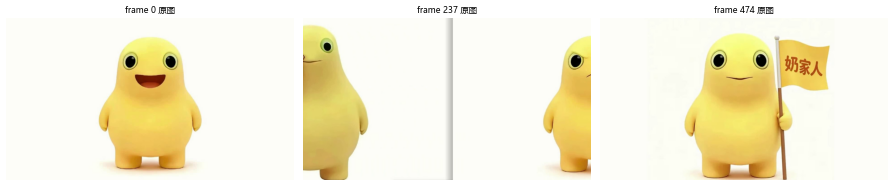

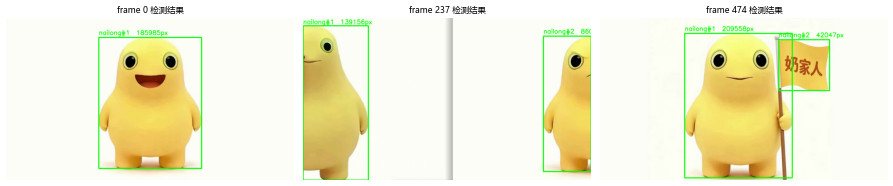

In [32]:
print('=== 6. 代表性帧的结果对比 ===')
cap2 = cv2.VideoCapture('res/nl_yellow_video.mp4')
picks = [0, 237, 474]
raws, viss = [], []
for idx in picks:
    cap2.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, fr = cap2.read()
    if not ok:
        continue
    bs = detect(fr)
    raws.append(fr)
    viss.append(annotate(fr, bs))
    print(f'frame {idx:3d}: {len(bs)} 个目标 -> {[(b[0], b[1], b[2], b[3]) for b in bs]}')
cap2.release()
show_img(*raws, titles=[f'frame {i} 原图' for i in picks])
show_img(*viss, titles=[f'frame {i} 检测结果' for i in picks])

---
## 参数怎么调（改一个看一个）

| 想解决什么 | 动哪个参数 | 往哪调 |
| --- | --- | --- |
| 目标**漏检**（该有的框没有） | `HI` 的 H 上限 / `LO` 的 S、V 下限 | H 区间**放宽**；S、V 下限**调低** |
| 背景/地面**被误检** | `LO` 的 S 下限 | **调高**（把不够纯的颜色排掉） |
| 掩膜**到处是小白点** | 开运算核 | **加大**（9→15） |
| 一只奶蛙被拆成**好几个框** | 闭运算核 | **加大**（15→25） |
| 小反光被当成目标 | `MIN_AREA` | **调大**（3000→8000） |
| 画面边缘半只奶蛙被丢掉 | `MIN_AREA` | **调小** |

> 💡 **调参顺序**（讲义第 5 章的建议）：**先调 S 下限**（剔掉灰白）→ **再调 V 下限**（剔掉过暗/过亮）
> → **最后微调 H 宽度**。按这个顺序走比随机改数字快得多。

下面这张表可以直接跑出来看：

In [33]:
print('=== 7. 参数实验：形态学核 & min_area 的影响（9 帧采样）===')
cap3 = cv2.VideoCapture('res/nl_yellow_video.mp4')
sample_idx = [0, 60, 118, 180, 237, 300, 356, 420, 474]
frames_sample = []
for idx in sample_idx:
    cap3.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, fr = cap3.read()
    if ok:
        frames_sample.append(fr)
cap3.release()

print(f'{"闭运算核":>8} {"min_area":>9}   {"共检出":>6}   每帧')
preset = [(0, 3000), (15, 3000), (25, 3000), (15, 5000), (15, 10000)]
result = {}
for close_ks, ma in preset:
    tot, per = 0, []
    for fr in frames_sample:
        hsv = cv2.cvtColor(fr, cv2.COLOR_BGR2HSV_FULL)
        m = cv2.inRange(hsv, LO, HI)
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((9, 9), np.uint8))
        if close_ks:
            m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((close_ks, close_ks), np.uint8))
        cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        k = sum(1 for c in cs if cv2.contourArea(c) > ma)
        tot += k
        per.append(k)
    result[(close_ks, ma)] = tot
    print(f'{close_ks:>8} {ma:>9}   {tot:>6}   {per}')
print()
print(f'→ 不加闭运算会把一只奶蛙拆成好几个小框（共 {result[(0, 3000)]} 个）；'
      f'加 15 或 25 就合并成整只（{result[(15, 3000)]} / {result[(25, 3000)]} 个）。')
d3, d10 = result[(15, 3000)], result[(15, 10000)]
if d10 < d3:
    print(f'→ min_area 从 3000 提到 10000：少了 {d3 - d10} 个（{d3} → {d10}）——'
          f'画面边缘"只露一半"的目标会被丢掉。')
else:
    print(f'→ min_area 从 3000 提到 10000：这 9 帧里没变化（{d3} → {d10}），'
          f'因为采样的这几帧里没有"刚过 3000 像素"的边缘目标。')

=== 7. 参数实验：形态学核 & min_area 的影响（9 帧采样）===
    闭运算核  min_area      共检出   每帧
       0      3000       16   [1, 1, 2, 1, 2, 2, 1, 3, 3]
      15      3000       14   [1, 1, 2, 1, 2, 2, 1, 2, 2]
      25      3000       12   [1, 1, 2, 1, 2, 2, 1, 1, 1]
      15      5000       14   [1, 1, 2, 1, 2, 2, 1, 2, 2]
      15     10000       14   [1, 1, 2, 1, 2, 2, 1, 2, 2]

→ 不加闭运算会把一只奶蛙拆成好几个小框（共 16 个）；加 15 或 25 就合并成整只（14 / 12 个）。
→ min_area 从 3000 提到 10000：这 9 帧里没变化（14 → 14），因为采样的这几帧里没有"刚过 3000 像素"的边缘目标。


---
## 还能怎么改进（按性价比排序）

1. **加 ROI**：如果只关心画面中间那一格，先切 ROI 再检测 —— 计算量直接按面积降，
   别的宫格的奶蛙也不会混进来（讲义第 2 章：ROI 是性价比最高的抗干扰手段）；
2. **换 `connectedComponentsWithStats`**：不用轮廓，直接数连通块，**比 `findContours` 更快**，
   而且天然给出每个块的面积/外接矩形。缺点是拿不到轮廓的层级和形状特征
   （想判断"这是圆的还是长的"就还得用轮廓）；
3. **多帧稳定性**：单帧偶尔会闪一下（误检/漏检）。可以**对连续几帧的框做匹配+投票**，
   或者对掩膜做时间上的中值，让结果更稳；
4. **光照/白平衡变化大时**：把 H 区间放宽没用的话，可以改用 **Lab 的 a/b 通道** 或
   **自适应阈值**（讲义第 3 章、第 5 章都提过）；
5. **目标不只靠颜色能区分时**（比如要和别的东西区分、或者颜色会变）：
   那就该上 **YOLO** 了 —— 这正是教材第 2 章要讲的内容。

## 常见坑自查

- [ ] 用了 `COLOR_BGR2HSV` 而不是 `COLOR_BGR2HSV_FULL`？→ H 区间全部错位；
- [ ] `VideoWriter` 的 `frameSize` 写成了 `(高, 宽)`？→ 静默生成 0 字节文件；
- [ ] 忘了 `cap.release()` / `writer.release()`？→ 视频打不开；
- [ ] `findContours` 喂了彩色图？→ `(-215:Assertion failed)`；
- [ ] 掩膜全黑时还去 `max(contours, ...)`？→ `ValueError: max() arg is an empty sequence`；
- [ ] 只看了统计数字没看图？→ 漏检/误检都是"数字看着还行、图上很明显"。

In [34]:
cap.release()
print('全部跑完。产物：')
print('  out/nl_yellow_result.mp4   —— 475 帧的标注视频（前提是上面显示 VideoWriter 可用）')
print('参数回顾： HSV_FULL  H %s~%s  S>=%s  V>=%s   |   开运算 9x9 + 闭运算 15x15   |   min_area=%s'
      % (LO[0], HI[0], LO[1], LO[2], MIN_AREA))

全部跑完。产物：
  out/nl_yellow_result.mp4   —— 475 帧的标注视频（前提是上面显示 VideoWriter 可用）
参数回顾： HSV_FULL  H 25~55  S>=60  V>=120   |   开运算 9x9 + 闭运算 15x15   |   min_area=3000
